# Đánh giá Decision Tree tốt nhất

Chọn siêu tham số bằng CV F1-macro trên tập train.
Tập test chỉ dùng để đánh giá; Decision Tree nhận đặc trưng gốc, không chuẩn hóa.

## 1. Thư viện và đường dẫn

In [1]:
import json
import re
from pathlib import Path
import sys

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.tree import plot_tree

project_dir = Path.cwd().resolve()
if project_dir.name == "decision_tree":
    project_dir = project_dir.parents[1]
elif project_dir.name == "models":
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))

from models.common import read_split, timestamp, write_json
from models.reporting import SUMMARY_COLUMNS

model_dir = project_dir / "models" / "decision_tree"
pd.set_option("display.max_columns", None)

## 2. Đọc model và dữ liệu

In [2]:
artifact = joblib.load(model_dir / "training_results.joblib")
search = artifact["search"]
model = joblib.load(model_dir / "model.joblib")
X_train, y_train = read_split("train")
X_test, y_test = read_split("test")
classes = model.classes_.tolist()
results = search.cv_results_
best_index = int(search.best_index_)

## 3. Siêu tham số tốt nhất

In [3]:
display(pd.DataFrame([search.best_params_]))

,ccp_alpha,criterion,max_depth,min_samples_leaf,min_samples_split
0,0.0,gini,None,1,2


## 4. Bảng tổng hợp

In [ ]:
train_prediction = model.predict(X_train)
prediction = model.predict(X_test)

options = {"labels": classes, "average": "macro", "zero_division": 0}
summary = pd.DataFrame([{
    "Model": "Decision Tree", "Configuration": "GridSearch",
    "CV_accuracy_mean": float(results["mean_test_accuracy"][best_index]),
    "CV_f1_macro_mean": float(results["mean_test_f1_macro"][best_index]),
    "CV_f1_macro_std": float(results["std_test_f1_macro"][best_index]),
    "Test_accuracy": float(accuracy_score(y_test, prediction)),
    "Test_precision_macro": float(precision_score(y_test, prediction, **options)),
    "Test_recall_macro": float(recall_score(y_test, prediction, **options)),
    "Test_f1_macro": float(f1_score(y_test, prediction, **options)),
    "Train_f1_macro": float(f1_score(y_train, train_prediction, **options)),
    "CV_train_validation_gap_F1": float(
        results["mean_train_f1_macro"][best_index] - results["mean_test_f1_macro"][best_index]
    ),
    "Preprocessing": "None (raw features)",
    "Best_grid_parameters": json.dumps(search.best_params_, sort_keys=True),
}], columns=SUMMARY_COLUMNS)
display(summary)

,Model,Configuration,CV_accuracy_mean,CV_f1_macro_mean,CV_f1_macro_std,Test_accuracy,Test_precision_macro,Test_recall_macro,Test_f1_macro,Train_f1_macro,CV_train_validation_gap_F1,Preprocessing,Best_grid_parameters
0,Decision Tree,GridSearch,0.985227,0.985209,0.00681,0.979545,0.980598,0.979545,0.979423,1.0,0.014791,None (raw features),"{""ccp_alpha"": 0.0, ""criterion"": ""gini"", ""max_d..."


## 5. Kết quả GridSearch

In [5]:
grid_rows = []
for i, parameters in enumerate(results["params"]):
    grid_rows.append({
        "Model": "Decision Tree", "Candidate": i + 1,
        "Parameters": json.dumps(parameters, sort_keys=True),
        "Rank_CV_F1_macro": int(results["rank_test_f1_macro"][i]),
        "Selected": i == best_index,
        "CV_accuracy_mean": float(results["mean_test_accuracy"][i]),
        "CV_f1_macro_mean": float(results["mean_test_f1_macro"][i]),
        "CV_f1_macro_std": float(results["std_test_f1_macro"][i]),
    })
grid = pd.DataFrame(grid_rows)
display(grid)

,Model,Candidate,Parameters,Rank_CV_F1_macro,Selected,CV_accuracy_mean,CV_f1_macro_mean,CV_f1_macro_std
0,Decision Tree,1,"{""ccp_alpha"": 0.0, ""criterion"": ""gini"", ""max_d...",13,False,0.871591,0.844597,0.034611
1,Decision Tree,2,"{""ccp_alpha"": 0.0, ""criterion"": ""gini"", ""max_d...",13,False,0.871591,0.844597,0.034611
2,Decision Tree,3,"{""ccp_alpha"": 0.0, ""criterion"": ""gini"", ""max_d...",15,False,0.871023,0.844029,0.035133
3,Decision Tree,4,"{""ccp_alpha"": 0.0, ""criterion"": ""gini"", ""max_d...",15,False,0.871023,0.844029,0.035133
4,Decision Tree,5,"{""ccp_alpha"": 0.0, ""criterion"": ""gini"", ""max_d...",1,True,0.985227,0.985209,0.006810
5,Decision Tree,6,"{""ccp_alpha"": 0.0, ""criterion"": ""gini"", ""max_d...",2,False,0.982955,0.982969,0.005969
6,Decision Tree,7,"{""ccp_alpha"": 0.0, ""criterion"": ""gini"", ""max_d...",6,False,0.978409,0.978433,0.009801
7,Decision Tree,8,"{""ccp_alpha"": 0.0, ""criterion"": ""gini"", ""max_d...",7,False,0.977841,0.977899,0.010066
8,Decision Tree,9,"{""ccp_alpha"": 0.0, ""criterion"": ""entropy"", ""ma...",8,False,0.977841,0.977536,0.006330
9,Decision Tree,10,"{""ccp_alpha"": 0.0, ""criterion"": ""entropy"", ""ma...",9,False,0.977841,0.977519,0.009336


## 6. Vẽ Decision Tree với siêu tham số tốt nhất

Vẽ toàn bộ cây trong `model.joblib`, chính là cây được chọn bởi
`search.best_estimator_` và fit lại trên toàn bộ tập train.
Ngưỡng chia nhánh dùng đơn vị của đặc trưng gốc. Mỗi nút hiển thị điều kiện chia,
độ hỗn tạp, số mẫu và lớp dự đoán; dòng `value` gồm 22 lớp được ẩn cho dễ đọc.

Ảnh PNG và SVG được lưu trong cùng thư mục. Mở SVG để phóng to từng nút;
hình này không giới hạn độ sâu hiển thị.

Cây tốt nhất: depth=17, leaves=38, nodes=75
Siêu tham số: {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}


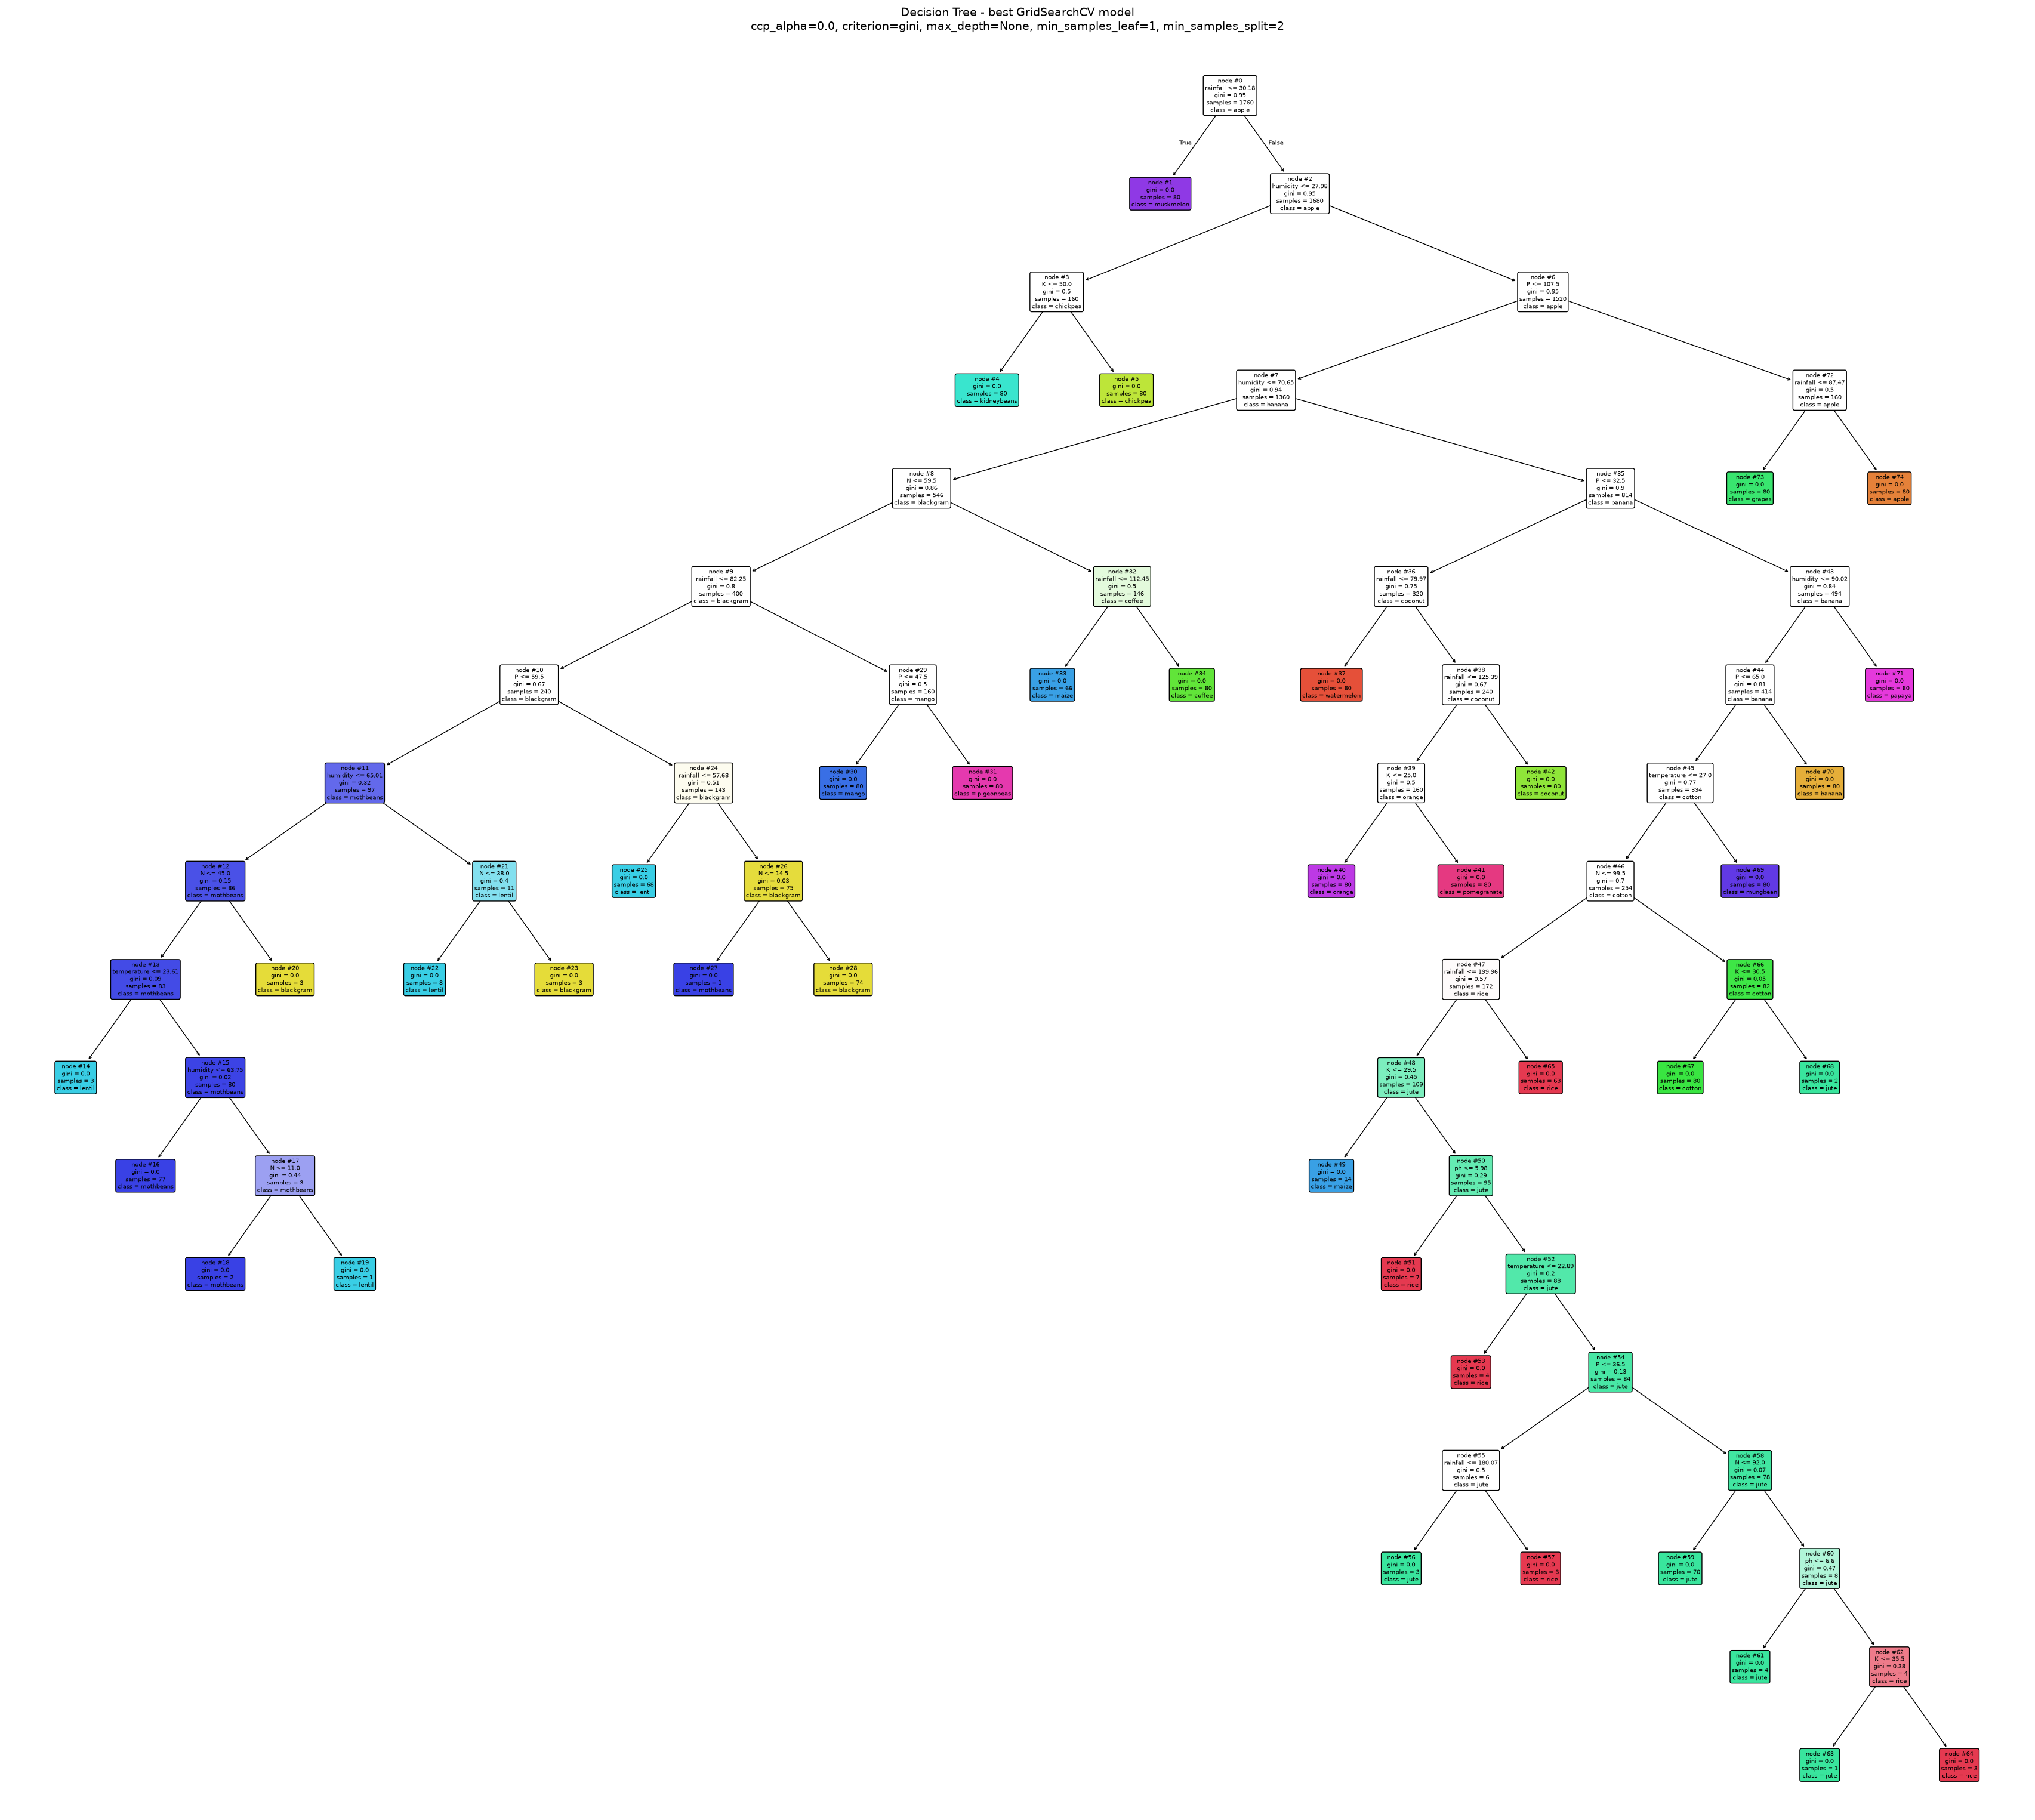

In [6]:
depth = int(model.get_depth())
leaves = int(model.get_n_leaves())
print(f"Cây tốt nhất: depth={depth}, leaves={leaves}, nodes={model.tree_.node_count}")
print("Siêu tham số:", search.best_params_)

fig, ax = plt.subplots(figsize=(max(20, min(80, leaves * 0.9)), max(10, depth * 1.8)))
annotations = plot_tree(
    model,
    feature_names=X_train.columns.tolist(),
    class_names=classes,
    filled=True,
    rounded=True,
    node_ids=True,
    precision=2,
    fontsize=7,
    ax=ax,
)
# Vector số mẫu của 22 lớp quá dài; giữ điều kiện, impurity, samples và class.
for annotation in annotations:
    annotation.set_text(re.sub(
        r"\nvalue = \[.*?\]", "", annotation.get_text(), flags=re.DOTALL
    ))

parameters_text = ", ".join(f"{key}={value}" for key, value in search.best_params_.items())
ax.set_title(f"Decision Tree - best GridSearchCV model\n{parameters_text}", fontsize=14, pad=20)
fig.tight_layout()
for extension in ("png", "svg"):
    fig.savefig(model_dir / f"best_decision_tree.{extension}", dpi=140, bbox_inches="tight")
plt.show()
plt.close(fig)

## 7. Lưu kết quả đánh giá

In [7]:
evaluated_at = timestamp()
evaluation = {
    "model_name": "Decision Tree", "evaluated_at": evaluated_at,
    "tables": {
        "Tong_hop": summary.to_dict(orient="records"),
        "GridSearch": grid.to_dict(orient="records"),
    },
}
selected = summary.iloc[0]
metadata = {
    "model_file": "model.joblib", "model_name": "Decision Tree",
    "estimator": "DecisionTreeClassifier", "configuration": "GridSearch",
    "parameters": search.best_params_, "preprocessing": "None (raw features)",
    "input_format": "Unscaled feature values in the order listed in features",
    "features": X_train.columns.tolist(), "classes": classes,
    "selection_metric": "CV_f1_macro_mean",
    "cv_f1_macro_mean": float(selected["CV_f1_macro_mean"]),
    "cv_f1_macro_std": float(selected["CV_f1_macro_std"]),
    "train_samples": len(X_train), "test_samples": len(X_test),
    "n_splits": search.n_splits_, "cv_method": str(search.cv),
    "training_finished_at": artifact["finished_at"],
    "versions": artifact["versions"], "evaluated_at": evaluated_at,
    "tree": {
        "depth": int(model.get_depth()), "leaves": int(model.get_n_leaves()),
        "node_count": int(model.tree_.node_count),
        "visualization_png": "best_decision_tree.png",
        "visualization_svg": "best_decision_tree.svg",
    },
    "test_metrics": {
        "accuracy": float(selected["Test_accuracy"]),
        "precision_macro": float(selected["Test_precision_macro"]),
        "recall_macro": float(selected["Test_recall_macro"]),
        "f1_macro": float(selected["Test_f1_macro"]),
    },
}
write_json(model_dir / "model_metadata.json", metadata)
write_json(model_dir / "evaluation_results.json", evaluation)